# Cornell AQEC vs FWM tails on Shirol's chip

**Question.** Roy et al. (Cornell, *Error semitransparent universal control of a bosonic logical qubit*,
`sources/`) protect their logical qubit with a two-step **active** QEC (AQEC). It has two steps: a 1 μs GRAPE pulse,
then a 1.2 μs transmon readout and reset. Our method is an **FWM tail**: two pump combs that put a lost photon back
(`FWM_tails.ipynb`). Which does better after the same gate, on the same chip?

**What this notebook does.** It puts the best possible version of their AQEC on *our* setup:
- Shirol's chip (`AQEC/device.py`) and the odd kitten code $(|1\rangle+|5\rangle)/\sqrt2,\ |3\rangle$;
- the same 1.1 μs EsT X gate as `FWM_tails.ipynb` (seed 24, `pulses/dgrape/u_X_est_err_closed_s24.npy`).

Their correcting operation is made **perfect**, but photon loss and transmon decay act during all 2.2 μs it takes.
The result is an **upper bound** for their scheme on our chip, to be set against our trained FWM tails, which are real
pulses. Section 5 then trains a **real** AQEC pulse on our chip, closed-system as the paper did, and scores it the same way.
Section 6 trains the whole step in the open system, with losses in the cost.

**Contents.**
1. How their AQEC works.
2. The idealised simulation.
3. Results (tables 1–5).
4. Context: the same idealised AQEC on the paper's own chip.
5. A real AQEC pulse trained on Shirol's chip, closed system (Tables 7–11).
6. The AQEC step trained in the open system (Tables 12–16).
7. Conclusions and next steps.

Code: `DGRAPE/aqec_ideal.py` (the ideal step), `DGRAPE/aqec_ideal_run.py` (writes `tables/aqec_ideal_*.csv`),
`validation/test_aqec_ideal.py` (11 checks); `DGRAPE/aqec_pulse.py`, `DGRAPE/train_aqec_pulse.py` and
`DGRAPE/aqec_pulse_score.py` (the real pulse, Section 5, `tables/aqec_pulse_*.csv`); `DGRAPE/aqec_open.py`,
`DGRAPE/train_aqec_open.py` and `aqec_pulse_score.py --family open` (open-system training, Section 6,
`tables/aqec_open_*.csv`).

In [2]:
import os
import sys

if os.path.basename(os.path.abspath(".")) == "notebooks":   # the notebook lives in notebooks/; data paths are relative to the repo root
    os.chdir("..")
REPO_ROOT = os.path.abspath(".")
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display

from AQEC import device as dev
from DGRAPE import aqec_ideal as aq

np.seterr(divide="ignore", over="ignore", invalid="ignore")   # Accelerate matmul noise (benign, see CLAUDE.md)
pd.set_option("display.max_colwidth", 80)
os.makedirs("figures", exist_ok=True)
TWO_PI = 2 * np.pi
OKABE = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00", "#56B4E9"]

# Simulation tables (rerun: python3 DGRAPE/aqec_ideal_run.py single | B1 | B2; minutes each on an idle Mac)
SINGLE = pd.read_csv("tables/aqec_ideal_single.csv")
STAGES = pd.read_csv("tables/aqec_ideal_stages.csv")
B1 = pd.read_csv("tables/aqec_ideal_B1.csv")
B2 = pd.read_csv("tables/aqec_ideal_B2.csv")
# FWM tail references (FWM_tails.ipynb §6 and §8): the best tail, 0.8 us, start "QEC teeth" (tag t2), after the same gate
HELD = pd.read_csv("tables/fwm_tail_heldout_good.csv")
FWM1 = pd.read_csv("tables/fwm_tail_repeat_B1.csv").query("label == 'EsT-good' and system == 'open'")
FWM2 = pd.read_csv("tables/fwm_tail_repeat_B2.csv").query("label == 'EsT-good' and system == 'open' and n_r == 3")
# Context (section 4): the same idealised AQEC on the paper's own model, and the paper's Fig. A6 points
PAPER_IDEAL = pd.read_csv("tables/aqec_ideal_paper_chip.csv")
PAPER_A6 = pd.read_csv("tables/aqec_paper_A6.csv")


def pct(x):
    return f"{100 * x:+.2f} %"


def show(df, caption=None, fmt=None):
    sty = df.style.hide(axis="index")
    if fmt:
        sty = sty.format(fmt)
    if caption:
        sty = sty.set_caption(caption)
    display(sty)


print(f"Shirol chip: chi_ge/2pi = {dev.chi_ge / TWO_PI:.2f} MHz, K/2pi = {dev.K_a / TWO_PI * 1e3:.1f} kHz, "
      f"T1 storage = {1 / dev.kappa_a:.0f} us, T1 transmon = {dev.T1_GE:.0f} us")
print(f"photon loss rate at nbar = 3: {3 * dev.kappa_a:.4f} per us = {300 * dev.kappa_a:.2f} % per us")

Shirol chip: chi_ge/2pi = 1.12 MHz, K/2pi = 3.3 kHz, T1 storage = 136 us, T1 transmon = 50 us
photon loss rate at nbar = 3: 0.0221 per us = 2.21 % per us


# 1. How their AQEC works

**Their code.** An even "kitten" code: $|0_L\rangle = (|0\rangle+|4\rangle)/\sqrt2$, $|1_L\rangle = |2\rangle$.
Losing one photon turns these code words into odd **error words**, $|3\rangle$ and $|1\rangle$. The error words
still carry the logical information, so the loss can be undone.

**Step 1: one GRAPE pulse, 1 μs.** The cavity and the transmon are driven together (linear drives only). The pulse is
trained to do two things at once (their App. C, Eqs. C9–C10):
- leave a code word alone: $U|\psi_L\rangle|g\rangle = |\psi_L\rangle|g\rangle$;
- turn an error word back into the matching code word, **and flip the transmon** as a record that it did:
  $U|\psi_E\rangle|g\rangle = |\psi_L\rangle|e\rangle$.

It is not trained to be error transparent: a photon lost *during* this pulse is not handled on purpose.

**Step 2: readout and reset, 1.2 μs.**
- The transmon is measured.
- If it reads **e**, a π pulse returns it to g.
- If it reads **g**, nothing is done, but the step still lasts 1.2 μs.

Either way the transmon ends in g, so this works as an **unconditional reset**. The measurement result is only
bookkeeping (it says whether an error was corrected).

**The phase trick.** During the 1.2 μs the cavity is idle, so it picks up phases that would scramble the code:
- the storage Kerr phase on every branch;
- on the branch whose transmon sits in e, also the dispersive phase $\chi\,n$.

The GRAPE pulse pre-rotates each branch by the opposite phase, so that at the end of the window both branches are
right.

**Their simulation (Fig. A6).** The gates and the whole AQEC block were simulated with losses (Lindblad, their four
collapse operators). The measurement and reset were ideal.

The diagram below shows one AQEC step on the two branches.

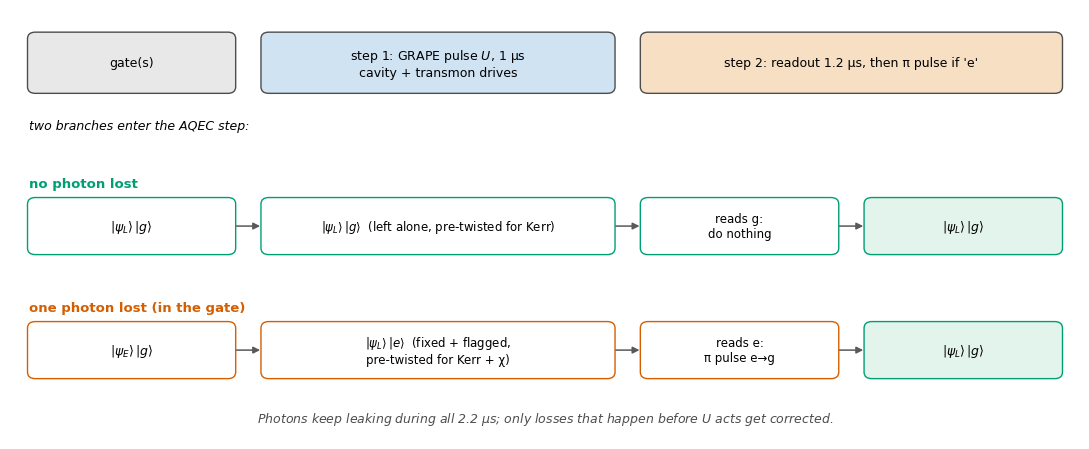

In [3]:
# Figure 1: one Cornell AQEC step, the two branches
def box(ax, x, y, w, h, text, fc, ec="0.3", fs=9, color="black", bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=fc, ec=ec, lw=1))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, color=color,
            fontweight="bold" if bold else "normal")


def arrow(ax, x0, y0, x1, y1, color="0.35"):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color=color, lw=1.1))


fig, ax = plt.subplots(figsize=(11, 4.6))
ax.set_xlim(0, 11); ax.set_ylim(0, 5.2); ax.axis("off")
# time line
box(ax, 0.2, 4.2, 2.1, 0.7, "gate(s)", "#e8e8e8")
box(ax, 2.6, 4.2, 3.6, 0.7, "step 1: GRAPE pulse $U$, 1 μs\ncavity + transmon drives", "#cfe3f3")
box(ax, 6.5, 4.2, 4.3, 0.7, "step 2: readout 1.2 μs, then π pulse if 'e'", "#f6dfc2")
ax.text(0.2, 3.75, "two branches enter the AQEC step:", fontsize=9, style="italic")
# no-loss branch
ax.text(0.2, 3.05, "no photon lost", fontsize=9.5, fontweight="bold", color=OKABE[2])
box(ax, 0.2, 2.25, 2.1, 0.65, r"$|\psi_L\rangle\,|g\rangle$", "white", ec=OKABE[2])
box(ax, 2.6, 2.25, 3.6, 0.65, r"$|\psi_L\rangle\,|g\rangle$  (left alone, pre-twisted for Kerr)", "white", ec=OKABE[2], fs=8.5)
box(ax, 6.5, 2.25, 2.0, 0.65, "reads g:\ndo nothing", "white", ec=OKABE[2], fs=8.5)
box(ax, 8.8, 2.25, 2.0, 0.65, r"$|\psi_L\rangle\,|g\rangle$", "#e3f4ec", ec=OKABE[2])
for x0, x1 in ((2.3, 2.6), (6.2, 6.5), (8.5, 8.8)):
    arrow(ax, x0, 2.575, x1, 2.575)
# loss branch
ax.text(0.2, 1.55, "one photon lost (in the gate)", fontsize=9.5, fontweight="bold", color=OKABE[4])
box(ax, 0.2, 0.75, 2.1, 0.65, r"$|\psi_E\rangle\,|g\rangle$", "white", ec=OKABE[4])
box(ax, 2.6, 0.75, 3.6, 0.65, r"$|\psi_L\rangle\,|e\rangle$  (fixed + flagged,"+"\npre-twisted for Kerr + χ)", "white", ec=OKABE[4], fs=8.5)
box(ax, 6.5, 0.75, 2.0, 0.65, "reads e:\nπ pulse e→g", "white", ec=OKABE[4], fs=8.5)
box(ax, 8.8, 0.75, 2.0, 0.65, r"$|\psi_L\rangle\,|g\rangle$", "#e3f4ec", ec=OKABE[2])
for x0, x1 in ((2.3, 2.6), (6.2, 6.5), (8.5, 8.8)):
    arrow(ax, x0, 1.075, x1, 1.075)
ax.text(5.5, 0.2, "Photons keep leaking during all 2.2 μs; only losses that happen before $U$ acts get corrected.",
        ha="center", fontsize=9, style="italic", color="0.3")
fig.tight_layout()
fig.savefig("figures/aqec_compare_protocol.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 1. One step of the Cornell AQEC.** Top row: the timeline. Lower rows: what happens to a branch with no photon
lost (green) and to a branch that lost one photon during the gate (red).
- $U$ leaves a code word alone, and turns an error word into the matching code word while flipping the transmon to e.
- The readout and the conditional π pulse put the transmon back in g on both branches.
- $U$ also pre-twists each branch, so the Kerr phase (both branches) and the χ phase (e branch) of the readout window
  cancel.

*Symbols:* $|\psi_L\rangle$ = a code word (logical state), $|\psi_E\rangle$ = the matching error word (one photon
fewer), g / e = transmon ground / excited state, χ = cavity–transmon dispersive shift, Kerr = the storage's
photon-number-dependent frequency shift.

**How it differs from our FWM tail.**

| | Cornell AQEC | our FWM tail |
|---|---|---|
| what fixes the error | a trained GRAPE pulse (linear cavity + transmon drives) | two pump combs (four-wave mixing) that add a photon back |
| where the entropy goes | the transmon, then a measurement and a reset | the readout resonator, which leaks the excitation away |
| needs a measurement | yes (1.2 μs here) | no |
| can it undo a loss exactly on the kitten code | yes, in principle (any unitary) | no: adding one photon leaves a $\sqrt5$ distortion on $|0_L\rangle$, best 0.935 |
| duration | 1 μs + 1.2 μs = 2.2 μs | 0.8 μs (our best tail) |

# 2. The idealised simulation

We keep everything that costs time and remove everything else: the correcting map is **perfect**, the measurement
and reset are **perfect**, but photons, the transmon and the readout keep decaying for the full 1 μs + 1.2 μs. One AQEC
step, applied to the state that comes out of the gate(s):

| step | what we do | what is ideal | what is lossy |
|---|---|---|---|
| 0 | reset any transmon excitation the gate left behind (trace the transmon out, put it in g) | the reset | nothing |
| 1 | let the state sit for **1 μs**, then undo the drift phase $e^{+iH_d\tau_1}$: their pulse "ends with the ideal unitary" | the phase undo | photon loss, transmon decay |
| 2 | apply the **ideal map**: code word → itself with g; error word → code word with e | the map, instantly | nothing |
| 3 | pre-twist with $e^{+iH_d\tau_2}$: cancels Kerr on the g branch and Kerr + χ on the e branch over the next 1.2 μs | the twist | nothing |
| 4 | let the state sit for **1.2 μs** (the readout window) | — | photon loss, transmon decay |
| 5 | reset the transmon to g, whatever it reads | the reset | nothing |

The ideal map in Kraus form (cavity ⊗ transmon), using the code and error words of `AQEC/odd_kitten.py`
($|0_E\rangle = (|0\rangle+\sqrt5|4\rangle)/\sqrt6$, $|1_E\rangle = |2\rangle$):

$$K_g = \big(1 - |0_E\rangle\langle 0_E| - |1_E\rangle\langle 1_E|\big)\otimes|g\rangle\langle g|, \qquad
K_e = \big(|0_L\rangle\langle 0_E| + |1_L\rangle\langle 1_E|\big)\otimes|e\rangle\langle g| .$$

**Which losses get fixed.** A photon lost during the gate or during step 1 is in the error words when the map acts,
so it is fixed exactly. A photon lost during step 4 comes after the map and is **not** fixed. Step 1 ends with the
ideal unitary, which is the optimistic placement. Putting all 2.2 μs *after* the map would be the pessimistic one:
on the paper's chip the two differ by about 1 %.

**Not modelled (all would make it worse).**
- an imperfect GRAPE pulse (closed-system error, losses that confuse it mid-pulse);
- measurement errors;
- the χ and Kerr phases picked up while the photon was being lost;
- dephasing and heating. These are in one extra row of Table 2 only.

**Variants and references.**

| name | what it is |
|---|---|
| **ideal AQEC** | steps 0–5 above (the main result) |
| ideal AQEC, strict | step 0 *drops* leftover transmon excitation (it counts as an error) instead of resetting it |
| no readout window | steps 0–2 and 5 only: 1 μs, no 1.2 μs wait (as if the readout were instant) |
| instant | steps 0, 2, 5 only: the map with no time cost at all (the ceiling) |
| gate(s) alone | no correction |
| gate(s) + 2.2 μs idle | do nothing for the same 2.2 μs, with the storage Kerr phase undone for free in the decoding (a fair "same time" memory reference) |
| FWM tail | our best trained tail after the same gate: 0.8 μs, start "QEC teeth" (`FWM_tails.ipynb` §6 and §8) |

**Setup.** DGRAPE's Lindblad model on Shirol's chip (`DGRAPE/model.py`), higher-order terms on, the **decay set**
(storage photon loss, readout decay, transmon decay), n_c = 24, one readout level. One level is exact, because
neither the gate nor this step ever puts a photon in the readout. Score: process fidelity $F_{\rm pro}$ on the code
against $X^N$, transmon in g. This is the same score as `FWM_tails.ipynb`, so the numbers can be compared directly.

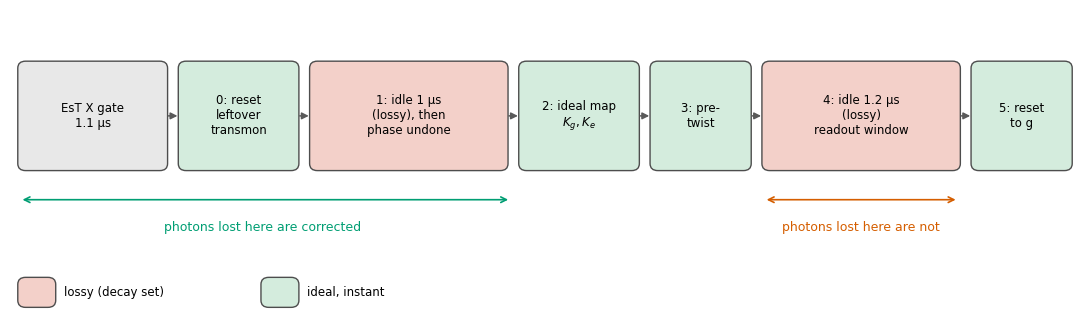

In [4]:
# Figure 2: the idealised step as simulated
fig, ax = plt.subplots(figsize=(11, 3.3))
ax.set_xlim(0, 11); ax.set_ylim(0, 3.4); ax.axis("off")
LOSSY, IDEAL = "#f3d0c9", "#d4ecdd"
blocks = [  # x, w, text, colour
    (0.1, 1.5, "EsT X gate\n1.1 μs", "#e8e8e8"),
    (1.75, 1.2, "0: reset\nleftover\ntransmon", IDEAL),
    (3.1, 2.0, "1: idle 1 μs\n(lossy), then\nphase undone", LOSSY),
    (5.25, 1.2, "2: ideal map\n$K_g, K_e$", IDEAL),
    (6.6, 1.0, "3: pre-\ntwist", IDEAL),
    (7.75, 2.0, "4: idle 1.2 μs\n(lossy)\nreadout window", LOSSY),
    (9.9, 1.0, "5: reset\nto g", IDEAL),
]
for x, w, t, c in blocks:
    box(ax, x, 1.6, w, 1.2, t, c, fs=8.5)
for (x, w, *_), (x2, *_) in zip(blocks[:-1], blocks[1:]):
    arrow(ax, x + w, 2.2, x2, 2.2)
ax.annotate("", xy=(5.15, 1.25), xytext=(0.1, 1.25), arrowprops=dict(arrowstyle="<->", color=OKABE[2], lw=1.2))
ax.text(2.6, 0.9, "photons lost here are corrected", ha="center", fontsize=9, color=OKABE[2])
ax.annotate("", xy=(9.75, 1.25), xytext=(7.75, 1.25), arrowprops=dict(arrowstyle="<->", color=OKABE[4], lw=1.2))
ax.text(8.75, 0.9, "photons lost here are not", ha="center", fontsize=9, color=OKABE[4])
box(ax, 0.1, 0.05, 0.35, 0.3, "", LOSSY); ax.text(0.55, 0.2, "lossy (decay set)", va="center", fontsize=8.5)
box(ax, 2.6, 0.05, 0.35, 0.3, "", IDEAL); ax.text(3.05, 0.2, "ideal, instant", va="center", fontsize=8.5)
fig.tight_layout()
fig.savefig("figures/aqec_compare_ideal.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 2. The idealised AQEC step as simulated.** The grey box is the gate, red boxes run the open-system model, and
green boxes are perfect and take no time. The arrows below mark which photon losses the map can still undo (green)
and which it cannot (red).
*Symbols:* $K_g, K_e$ = the two Kraus operators of the ideal map (Section 2); "phase undone" = $e^{+iH_d\tau_1}$
applied at the end of step 1; pre-twist = $e^{+iH_d\tau_2}$, $\tau_2$ = 1.2 μs.

# 3. Results

## 3.1 One gate + one AQEC step, stage by stage

In [5]:
st = STAGES.query("channels == 'decay'")[["stage", "time_us", "F_pro", "P_code", "P_error", "P_e"]].copy()
st.columns = ["stage", "time (μs)", "F_pro", "on code words", "on error words", "transmon in e"]
show(st, "Table 1. One EsT X gate + one ideal AQEC step, decay set",
     {"time (μs)": "{:.1f}", "F_pro": "{:.5f}", "on code words": "{:.4f}", "on error words": "{:.4f}",
      "transmon in e": "{:.4f}"})

stage,time (μs),F_pro,on code words,on error words,transmon in e
after the gate,1.1,0.96706,0.9701,0.0243,0.0067
step 0: leftover transmon excitation reset,1.1,0.96811,0.9701,0.0243,0.0000
"step 1: 1 us lossy idle, drift phase undone",2.1,0.94706,0.9496,0.0447,0.0000
step 2a: ideal map (scored with an instant reset),2.1,0.98942,0.9943,-0.0000,0.0447
step 2b: 1.2 us readout window + reset,3.3,0.96307,0.9685,0.0254,0.0000


**Table 1. One EsT X gate followed by one ideal AQEC step, stage by stage, decay set.**

*Symbols:*
- "on code words" / "on error words" = the population in span{$|0_L\rangle, |1_L\rangle$} / span{$|0_E\rangle, |1_E\rangle$}, averaged over the two logical inputs;
- "transmon in e" = the population with the transmon in $|e\rangle$;
- the remaining ≈ 0.5 % is two losses, transmon decay, or the gate's own coherent error; "−0.0000" is round-off.

**What happens at each stage.** The gate's output is 97.0 % on the code words and 2.4 % on the error words, from one
photon lost during the gate.
- **Step 0.** Resetting the transmon excitation the gate left behind (0.67 %) gains +0.10 %.
- **Step 1.** In 1 μs of waiting another 2.0 % loses a photon, so the error words grow to 4.5 % and $F_{\rm pro}$ falls to 0.947.
- **Step 2a.** The ideal map moves *all* of the error-word population back to the code and flips the transmon for it (4.5 % in e). If the step ended here, $F_{\rm pro}$ would be 0.9894, +2.24 % over the gate alone.
- **Step 2b.** During the 1.2 μs readout window, 2.5 % of the population loses a photon again. These losses come after the map and stay uncorrected, so $F_{\rm pro}$ ends at 0.9631.

**What it shows.** The storage loses 2.2 % of its population per μs at $\bar n = 3$. So the 1.2 μs readout window
costs more (2.6 %) than the map gains over the gate alone (2.24 %). The readout window is the whole problem.

## 3.2 One gate: ideal AQEC against no correction and against the FWM tail

In [6]:
def n1_table(channels):
    s = SINGLE.query("channels == @channels")[["protocol", "time_us", "F_pro"]].copy()
    cond = {"decay": "train", "all": "all_ch"}[channels]
    fwm = HELD.query("tag == 'X_tail_estg_T08_t2' and condition == @cond").iloc[0]
    s = pd.concat([s, pd.DataFrame([{"protocol": "gate + FWM tail 0.8 μs (trained, QEC-teeth start)",
                                     "time_us": 1.9, "F_pro": fwm.F_pro}])], ignore_index=True)
    alone = s.F_pro.iloc[0]
    s["gain vs gate alone"] = (s.F_pro - alone).map(pct)
    s.loc[0, "gain vs gate alone"] = "—"
    s.columns = ["protocol", "time (μs)", "F_pro", "gain vs gate alone"]
    return s


show(n1_table("decay"), "Table 2a. One EsT X gate, decay set (photon loss, readout decay, transmon decay)",
     {"time (μs)": "{:.1f}", "F_pro": "{:.5f}"})
show(n1_table("all"), "Table 2b. The same with every channel (plus dephasing and heating)",
     {"time (μs)": "{:.1f}", "F_pro": "{:.5f}"})

protocol,time (μs),F_pro,gain vs gate alone
gate alone,1.1,0.96706,—
gate + 2.2 us idle (Kerr decoded),3.3,0.92146,-4.56 %
gate + ideal AQEC,3.3,0.96307,-0.40 %
"gate + ideal AQEC, strict",3.3,0.96091,-0.62 %
gate + no readout window,2.1,0.98942,+2.24 %
gate + instant,1.1,0.99006,+2.30 %
"gate + FWM tail 0.8 μs (trained, QEC-teeth start)",1.9,0.97027,+0.32 %


protocol,time (μs),F_pro,gain vs gate alone
gate alone,1.1,0.95733,—
gate + 2.2 us idle (Kerr decoded),3.3,0.90671,-5.06 %
gate + ideal AQEC,3.3,0.95029,-0.70 %
"gate + ideal AQEC, strict",3.3,0.94687,-1.05 %
gate + no readout window,2.1,0.97943,+2.21 %
gate + instant,1.1,0.98277,+2.54 %
"gate + FWM tail 0.8 μs (trained, QEC-teeth start)",1.9,0.95760,+0.03 %


**Table 2. One gate, then one correction step:** (a) the decay set, (b) every channel. The gain is the difference in
$F_{\rm pro}$ from the same gate with no correction.
*Symbols:* time = from the start of the gate to the end of the correction.

**What it shows.** For one gate, the FWM tail wins.
- **The ideal AQEC loses:** −0.40 % (−0.70 % with every channel). The trained 0.8 μs FWM tail gains +0.32 % (+0.03 %).
- **Without the readout window**, the same ideal map would gain +2.24 %, seven times the FWM tail.
- **Doing nothing for 2.2 μs** costs 4.6 %. Against that same-time reference the ideal AQEC is 4.2 % better, but a gate does not have to wait.
- **"Strict"** (the gate's leftover transmon excitation counted as an error, not reset) is 0.2 % lower. That is what the reset is worth after one gate.

The FWM tail is 2.75× shorter and needs no measurement, and that outweighs its imperfect repair: 0.935 of a lost
photon's information, against 1 for the ideal map.

## 3.3 N gates, then one AQEC (the paper's Fig. A6b protocol)

In [7]:
NS = [1, 2, 3, 5, 10, 15, 20]
p1 = B1.pivot(index="N", columns="protocol", values="F_pro")
f1 = FWM1.pivot(index="N", columns="tail", values="F_pro")
t1 = pd.DataFrame({
    "N": NS,
    "gates only": p1.loc[NS, "gates only"].values,
    "+ 2.2 μs idle": p1.loc[NS, "gates + 2.2 us idle (Kerr decoded)"].values,
    "+ ideal AQEC (2.2 μs)": p1.loc[NS, "gates + ideal AQEC"].values,
    "+ ideal AQEC, strict": p1.loc[NS, "gates + ideal AQEC, strict"].values,
    "+ no readout window (1 μs)": p1.loc[NS, "gates + no readout window"].values,
    "+ instant": p1.loc[NS, "gates + instant"].values,
    "+ FWM tail (0.8 μs)": f1.loc[NS, "tail"].values,
})
check = np.max(np.abs(p1["gates only"].values - f1["none"].values[: len(p1)]))
show(t1, "Table 3. N EsT X gates back to back, then one correction step (F_pro against X^N)",
     {c: "{:.4f}" for c in t1.columns if c != "N"})
print(f"check: our 'gates only' column equals FWM_tails' (n_r = 2) to {check:.1e}")

N,gates only,+ 2.2 μs idle,+ ideal AQEC (2.2 μs),"+ ideal AQEC, strict",+ no readout window (1 μs),+ instant,+ FWM tail (0.8 μs)
1,0.9671,0.9215,0.9631,0.9609,0.9894,0.9901,0.9703
2,0.9359,0.8919,0.9494,0.9463,0.9756,0.9765,0.9533
3,0.9050,0.8625,0.9346,0.9300,0.9606,0.9618,0.9345
5,0.8472,0.8076,0.9035,0.8958,0.9289,0.9306,0.8954
10,0.7195,0.6860,0.8094,0.7963,0.8326,0.8347,0.7864
15,0.6105,0.5825,0.7158,0.6976,0.7365,0.7387,0.6823
20,0.5200,0.4966,0.6326,0.6118,0.6511,0.6532,0.5932


check: our 'gates only' column equals FWM_tails' (n_r = 2) to 8.9e-16


**Table 3. N EsT X gates back to back, then one correction step (the paper's Fig. A6b protocol).** $F_{\rm pro}$ is
scored against $X^N$.
- "+ FWM tail" = the one-tail rows of `FWM_tails.ipynb` Figure 13 (`tables/fwm_tail_repeat_B1.csv`).
- The gates-only column equals that table's to 1e-15. This checks that one readout level (used here) and two (used there) agree.

**What it shows.**
- The ideal AQEC beats no correction from N = 2 (0.9494 vs 0.9359).
- It catches the FWM tail at N = 3 (0.9346 vs 0.9345) and then leads by more and more: +2.3 % at N = 10, +3.9 % at N = 20.
- **Why it pulls ahead:** after many gates there are many error words. The ideal map restores each one exactly, while an FWM repair keeps at most 0.935 of it. The AQEC's fixed window cost (about 2.6 %) is paid only once.

## 3.4 A correction after every gate (the paper's Fig. A6d protocol)

In [8]:
p2 = B2.pivot(index="N", columns="protocol", values="F_pro")
tp = B2.pivot(index="N", columns="protocol", values="time_us")
fw2 = FWM2.set_index("N")
t2 = pd.DataFrame({
    "N": NS,
    "gates only": p1.loc[NS, "gates only"].values,
    "ideal AQEC pairs": p2.loc[NS, "(gate + ideal AQEC) pairs"].values,
    "strict": p2.loc[NS, "(gate + ideal AQEC, strict) pairs"].values,
    "no readout window": p2.loc[NS, "(gate + no readout window) pairs"].values,
    "instant": p2.loc[NS, "(gate + instant) pairs"].values,
    "FWM tail pairs": fw2.loc[NS, "F_pro"].values,
    "time, AQEC (μs)": tp.loc[NS, "(gate + ideal AQEC) pairs"].values,
    "time, FWM (μs)": fw2.loc[NS, "time_us"].values,
})
show(t2, "Table 4. N (gate + correction) pairs (F_pro against X^N)",
     {**{c: "{:.4f}" for c in t2.columns[1:7]}, "time, AQEC (μs)": "{:.1f}", "time, FWM (μs)": "{:.1f}"})

N,gates only,ideal AQEC pairs,strict,no readout window,instant,FWM tail pairs,"time, AQEC (μs)","time, FWM (μs)"
1,0.9671,0.9631,0.9609,0.9894,0.9901,0.9702,3.3,1.9
2,0.9359,0.9495,0.9438,0.9806,0.9819,0.9475,6.6,3.8
3,0.9050,0.9366,0.9266,0.9717,0.9737,0.9252,9.9,5.7
5,0.8472,0.9121,0.8935,0.9547,0.9578,0.8839,16.5,9.5
10,0.7195,0.8548,0.8160,0.9139,0.9199,0.7911,33.0,19.0
15,0.6105,0.8024,0.7453,0.8755,0.8840,0.7110,49.5,28.5
20,0.5200,0.7546,0.6810,0.8394,0.8500,0.6414,66.0,38.0


**Table 4. A correction after every gate (the paper's Fig. A6d protocol).** "FWM tail pairs" = gate + 0.8 μs tail,
from `FWM_tails.ipynb` Figure 14 (`tables/fwm_tail_repeat_B2.csv`, open system, three readout levels). The time
columns give the total duration of the N pairs.

**What it shows.**
- **The ideal AQEC pairs lead from N = 2** (0.9495 vs 0.9475). At N = 20 they reach 0.755, against 0.641 for the FWM pairs and 0.520 for no correction.
- **They take 74 % longer:** 3.3 μs per pair against 1.9 μs.
- **Losses during the 1 μs pulse cost little.** "No readout window" and "instant" stay close together (0.839 vs 0.850 at N = 20). What separates them from the ideal AQEC is the 1.2 μs window.
- **The reset matters.** "Strict" falls 7 % below the ideal AQEC by N = 20. Each gate leaves 0.67 % in $|e\rangle$, which only the reset clears; an FWM tail cannot clear it.

## 3.5 Summary: break-even and the cost per gate

In [9]:
def first_win(F, ref):
    w = np.where(F > ref)[0]
    return int(w[0] + 1) if len(w) else None


def rate(N, F):
    # mean fidelity lost per gate (or per pair), from a straight-line fit over N = 1..20
    return -np.polyfit(N, F, 1)[0]


N = p1.index.values
none = p1["gates only"].values
rows = []
for label, F1, F2 in (
        ("ideal AQEC", p1["gates + ideal AQEC"].values, p2["(gate + ideal AQEC) pairs"].values),
        ("ideal AQEC, strict", p1["gates + ideal AQEC, strict"].values, p2["(gate + ideal AQEC, strict) pairs"].values),
        ("no readout window", p1["gates + no readout window"].values, p2["(gate + no readout window) pairs"].values),
        ("instant", p1["gates + instant"].values, p2["(gate + instant) pairs"].values),
        ("FWM tail 0.8 μs", f1["tail"].values[: len(N)], fw2["F_pro"].values[: len(N)])):
    rows.append({"correction": label,
                 "B1: beats gates only from N =": first_win(F1, none),
                 "B2: beats gates only from N =": first_win(F2, none),
                 "B2: loss per pair": rate(N, F2),
                 "B2 at N = 20": F2[-1]})
rows.append({"correction": "none (gates only)", "B1: beats gates only from N =": "—",
             "B2: beats gates only from N =": "—", "B2: loss per pair": rate(N, none), "B2 at N = 20": none[-1]})
t5 = pd.DataFrame(rows)
show(t5, "Table 5. When each correction starts to pay, and how fast the fidelity falls",
     {"B2: loss per pair": lambda x: f"{100 * x:.2f} %", "B2 at N = 20": "{:.4f}",
      "B1: beats gates only from N =": lambda x: x if isinstance(x, str) else ("never (N ≤ 20)" if pd.isna(x) else f"{int(x)}"),
      "B2: beats gates only from N =": lambda x: x if isinstance(x, str) else ("never (N ≤ 20)" if pd.isna(x) else f"{int(x)}")})

correction,B1: beats gates only from N =,B2: beats gates only from N =,B2: loss per pair,B2 at N = 20
ideal AQEC,2,2,1.09 %,0.7546
"ideal AQEC, strict",2,2,1.47 %,0.6810
no readout window,1,1,0.79 %,0.8394
instant,1,1,0.74 %,0.8500
FWM tail 0.8 μs,1,1,1.72 %,0.6414
none (gates only),—,—,2.34 %,0.5200


**Table 5. Break-even and the cost per pair.**
- **"Beats gates only from N ="** is the first N at which the corrected chain scores higher than the uncorrected one.
- **"Loss per pair"** is minus the slope of a straight line through $F_{\rm pro}(N)$, N = 1–20, in the after-every-gate protocol (Table 4). For "none" it is the loss per gate.

**What it shows.**
- **Loss per pair:** the ideal AQEC loses 1.09 %, the FWM tail 1.72 %, and no correction 2.34 % per gate.
- **Without the readout window** the AQEC would lose 0.79 %.
- **The overall picture:** with a perfect map, the readout window costs the AQEC the single-gate comparison. In a long chain it still wins clearly, because every repair is exact and the transmon is reset every time.

# 4. Context: the same idealised AQEC on the paper's own chip

Earlier in this study, the same idealised step was run on the **paper's own model** with their even kitten code and
their EsT X gate (`analysis/aqec_paper_model/`). That model is their notebook's Lindblad model, rebuilt in numpy; it
reproduces their closed LE fidelity 0.998623. The table compares it with the paper's own simulated points (their
Fig. A6, which used their real trained AQEC pulse). "Ideal AQEC" here is variant B of that run: 1 μs lossy, the map,
then 1.2 μs lossy, the same as Section 2.

In [10]:
pi = PAPER_IDEAL.query("gate == 'ET'")
b1p = pi.query("protocol == 'B1'").set_index("N")
b2p = pi.query("protocol == 'B2'").pivot(index="N", columns="variant", values="F")
a6 = PAPER_A6.query("gate == 'ET'").pivot(index="N", columns="protocol", values="F_pro")
NP = [n for n in (1, 2, 3, 5, 10, 15, 20) if n in b1p.index]
t6 = pd.DataFrame({
    "N": NP,
    "gates only": b1p.loc[NP, "none"].values,
    "B1: ideal AQEC": b1p.loc[NP, "B"].values,
    "B1: paper Fig. A6b": [a6.loc[n, "B1"] if n in a6.index else np.nan for n in NP],
    "B2: ideal AQEC": b2p.loc[NP, "B"].values,
    "B2: paper Fig. A6d": [a6.loc[n, "B2"] if n in a6.index and not np.isnan(a6.loc[n, "B2"]) else np.nan for n in NP],
})
show(t6, "Table 6. Paper's chip and even code, their EsT X gate (1 μs): ideal AQEC vs the paper's real AQEC pulse",
     {c: (lambda x: "—" if pd.isna(x) else f"{x:.4f}") for c in t6.columns if c != "N"})

N,gates only,B1: ideal AQEC,B1: paper Fig. A6b,B2: ideal AQEC,B2: paper Fig. A6d
1,0.9730,0.9686,0.9414,0.9686,0.9414
2,0.9470,0.9524,0.9237,0.9523,0.9073
3,0.9197,0.9349,0.9043,0.9360,0.8756
5,0.8692,0.9019,0.8701,0.9042,0.8241
10,0.7541,0.8224,0.7996,0.8263,0.7231
15,0.6495,0.7465,0.7296,0.7512,—
20,0.5505,0.6684,0.6604,0.6802,—


**Table 6. The same idealised AQEC on the paper's own chip, against their real pulse.** Even kitten code and their EsT X
gate (1 μs).
- *ideal AQEC* = variant B of `analysis/aqec_paper_model/` (`tables/aqec_ideal_paper_chip.csv`).
- *paper Fig. A6* = their simulated points with the real trained AQEC pulse (`tables/aqec_paper_A6.csv`). Their after-every-gate data stop at N = 10.

**What it shows: the real pulse costs a lot on top of the ideal step.**
- At N = 1 it gives 0.9414 against 0.9686, a gap of 2.7 %.
- With a correction after every gate it loses about 2.4 % per pair over N = 1–10, against 1.6 % for the ideal step: about 0.9 % more per pair.
- The likely causes are the pulse's own closed-system error, the losses during the pulse it was never trained to handle, and the phase corrections, which are only right for the no-jump branch.

**Why the one-AQEC-after-N-gates columns are not used.** There the gap shrinks to 0.8 % by N = 20. That cannot be the
pulse doing better. More likely their A6 gate model differs slightly from the one in their notebook, which is the one
we rebuilt: our gates-only chain falls faster than their curve suggests. So we read the pulse's cost from N = 1 and
from the after-every-gate protocol.

# 5. A real AQEC pulse, trained on Shirol's chip

Sections 2–3 assumed the correcting map is perfect and instant. Here we replace it with a **real GRAPE pulse**,
trained the way the paper trained theirs and the way we trained our Ord gate:
- **closed system:** no losses in the training cost;
- **scored afterwards in the open system:** the same Lindblad model and AQEC chain as Section 3.

**Closed or open training?** Closed, to match the paper (GRAPE on their Eqs. C9–C10, Lindblad only in Fig. A6) and
our Ord gate (`train_est_gate.py --variant ord`). Open-system training, like our d2 gate, could teach the pulse to
lose fewer photons along the way. It is the natural next step, at about 10 h per run.

**The target** (`DGRAPE/aqec_pulse.py`). One pulse of length $T$ (cavity + transmon drives) must:
- leave each of the six code cardinals alone, transmon in g;
- send each of the six error cardinals to its code cardinal, transmon in e;
- pre-twist every target by $e^{+iH_d\cdot 1.2\,\mu s}$, so the readout window's Kerr and χ phases cancel.

The cost is the Ord gate's: EST's $C_1$ (one minus the mean $|\langle{\rm target}|U|{\rm input}\rangle|^2$ over the 12
states) plus the drive cap. The g and e blocks may differ by a phase, because the readout and reset destroy that
coherence anyway.

**Settings.** The same drive limits as the EsT gate:
- bands ±27 / ±33 MHz and a 48 ns ramp;
- $|\varepsilon| \le 25$ rad/μs ≈ 4 MHz per drive, the paper's cap;
- **1 ns steps**, truncation $n_c = 20$ (checked at 24 and 28);
- the smooth seeded start, 4000 L-BFGS-B iterations.

**The runs.** Three lengths, 1, 1.5 and 2 μs, with two seeds each. Why 1 μs may be too short: the pulse must flip the
transmon only for even photon numbers, which needs it to resolve $\chi_{ge}$ = 1.12 MHz, about 0.9 μs. The paper's chip
has χ = 3.66 MHz, so its 1 μs pulse spans 3.7 cycles of χ. Ours spans 1.1 at 1 μs and 2.2 at 2 μs.

Commands:
- `python3 DGRAPE/train_aqec_pulse.py --duration-us T --seed s` (4–5 h each, six side by side on a loaded Mac);
- `python3 DGRAPE/aqec_pulse_score.py runs|single|channels|B1|B2` → `tables/aqec_pulse_*.csv`.

In [11]:
RUNS = pd.read_csv("tables/aqec_pulse_runs.csv")
PSINGLE = pd.read_csv("tables/aqec_pulse_single.csv")
PCHAN = pd.read_csv("tables/aqec_pulse_channels.csv")
PB1 = pd.read_csv("tables/aqec_pulse_B1.csv")
PB2 = pd.read_csv("tables/aqec_pulse_B2.csv")
BEST = {1.0: "aqec_T10_s42", 1.5: "aqec_T15_s43", 2.0: "aqec_T20_s42"}    # best closed F at n_c 24 per length

t7 = RUNS[["duration_us", "seed", "F_nc20", "F_nc24", "F_nc28", "F_code_nc24", "F_err_nc24", "frac_pinned",
           "minutes"]].copy()
t7.insert(2, "used", ["yes" if t in BEST.values() else "" for t in RUNS.tag])
t7.columns = ["length (μs)", "seed", "used below", "F, n_c 20 (trained)", "F, n_c 24", "F, n_c 28",
              "F code block (24)", "F error block (24)", "pre-image pinned", "minutes"]
show(t7, "Table 7. Closed-system training results, 12 conditions, 4000 iterations each",
     {"length (μs)": "{:.1f}", "F, n_c 20 (trained)": "{:.5f}", "F, n_c 24": "{:.5f}", "F, n_c 28": "{:.5f}",
      "F code block (24)": "{:.5f}", "F error block (24)": "{:.5f}", "pre-image pinned": "{:.2%}",
      "minutes": "{:.0f}"})

length (μs),seed,used below,"F, n_c 20 (trained)","F, n_c 24","F, n_c 28",F code block (24),F error block (24),pre-image pinned,minutes
1.0,42,yes,0.89915,0.86781,0.86466,0.86828,0.86733,9.45%,247
1.0,43,,0.94109,0.82565,0.81326,0.77023,0.88107,5.47%,248
1.5,42,,0.98762,0.98581,0.98580,0.98712,0.98450,1.78%,279
1.5,43,yes,0.99146,0.98909,0.98873,0.98790,0.99028,3.32%,279
2.0,42,yes,0.99993,0.99988,0.99988,0.99991,0.99984,0.00%,309
2.0,43,,0.99983,0.99956,0.99955,0.99944,0.99967,0.09%,309


**Table 7. Closed-system training results.** F = closed-system fidelity over the 12 conditions: six code cardinals
kept, six error cardinals fixed and flagged.
- $n_c$ 20 is the training truncation; 24 and 28 check for truncation artefacts.
- "Pre-image pinned" = the share of the optimiser's raw variables sitting at the box $|x| = 25$.
- Every run used all 4000 iterations.

**What it shows: 1 μs is not long enough, 1.5 μs nearly is, and 2 μs is.**
- **1 μs.** Both seeds stall well below EST's bar of 0.999, at 0.90 and 0.94.
  - The pulses also fall apart at higher truncation (0.83–0.87 at $n_c$ = 24): they push photons to the edge of the 20-level space.
  - 5–9 % of the pre-image sits at the box, so they ran out of drive.
- **1.5 μs.** 0.988 and 0.991, the same at 24 and 28. Both were still climbing slowly (about +1e-4 per 100 iterations) when they stopped.
- **2 μs.** Both seeds pass the bar: 0.99988 and 0.99956 at $n_c$ = 24, with nothing pinned.

**Why length matters.** The pulse must flip the transmon on even photon numbers only, which takes about
$1/\chi_{ge}$ ≈ 0.9 μs on this chip, plus time to reshape the cavity. On the paper's chip χ is three times larger, so
1 μs was enough there.

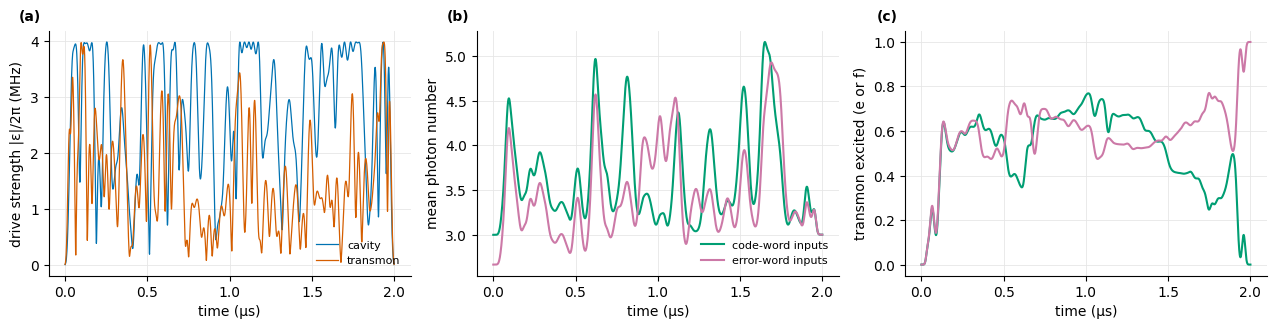

In [12]:
# Figure 3: the 2 us pulse: drive strengths, and what it does to the photon number and the transmon (closed system)
from DGRAPE import aqec_pulse as ap
from EST.grape_eigh import propagate_trajectory
from DGRAPE.model import operators

U2 = np.load("pulses/dgrape/u_aqec_T20_s42.npy")
sysA = ap.system(24)
P = np.abs(propagate_trajectory(U2, sysA.H0, sysA.Hc, sysA.inputs, ap.DT)) ** 2
ops = operators(24, 1)
nbar = P.transpose(0, 2, 1) @ np.real(np.diag(ops["n_a"]))
pexc = P.transpose(0, 2, 1) @ np.real(np.diag(ops["Pe"]) + np.diag(ops["Pf"]))
t = np.arange(P.shape[0]) * ap.DT
tu = np.arange(U2.shape[0]) * ap.DT

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].plot(tu, np.hypot(U2[:, 0], U2[:, 1]) / TWO_PI, color=OKABE[0], lw=0.9, label="cavity")
ax[0].plot(tu, np.hypot(U2[:, 2], U2[:, 3]) / TWO_PI, color=OKABE[4], lw=0.9, label="transmon")
ax[0].set_ylabel("drive strength |ε|/2π (MHz)"); ax[0].legend(frameon=False, fontsize=8)
for k, (col, lab) in enumerate(((OKABE[2], "code-word inputs"), (OKABE[3], "error-word inputs"))):
    sl = slice(6 * k, 6 * k + 6)
    ax[1].plot(t, nbar[:, sl].mean(1), color=col, label=lab)
    ax[2].plot(t, pexc[:, sl].mean(1), color=col, label=lab)
ax[1].set_ylabel("mean photon number"); ax[2].set_ylabel("transmon excited (e or f)")
ax[1].legend(frameon=False, fontsize=8)
for a_, letter in zip(ax, "abc"):
    a_.set_xlabel("time (μs)"); a_.grid(color="0.9", lw=0.6)
    for side in ("top", "right"):
        a_.spines[side].set_visible(False)
    a_.text(-0.02, 1.03, f"({letter})", transform=a_.transAxes, fontweight="bold", ha="right", va="bottom")
fig.tight_layout()
fig.savefig("figures/aqec_compare_pulse_T2.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 3. The trained 2 μs AQEC pulse** (seed 42), closed system, $n_c$ = 24.
- (a) Drive strengths. Both drives work at the 4 MHz cap for much of the pulse.
- (b) Mean photon number, averaged over the six code-word and the six error-word inputs.
- (c) Population with the transmon excited.

*Symbols:* $|\varepsilon|/2\pi$ = drive amplitude in MHz. The code cardinals hold 3 photons on average and the error cardinals 2.7, which is where the curves in (b) start.

**What it shows.** The pulse does not act gently. It pushes the cavity to about 3.6 photons on average (up to 6 for single inputs), and
keeps the transmon excited about half the time. Both matter once losses are on:
- more photons means more photon loss *during* the pulse;
- an excited transmon decays with $T_1$ = 50 μs.

In [13]:
def n1_real(channels):
    s = PSINGLE.query("channels == @channels").pivot(index="protocol", columns="duration_us", values="F_pro")
    order = ["real AQEC (as is)", "real AQEC (leftover transmon reset first)", "real AQEC, no readout window",
             "real AQEC, closed system (gate and step)", "ideal AQEC, same length"]
    s = s.loc[order]
    alone = SINGLE.query("channels == @channels and protocol == 'gate alone'").F_pro.iloc[0]
    cond = {"decay": "train", "all": "all_ch"}[channels]
    fwm = HELD.query("tag == 'X_tail_estg_T08_t2' and condition == @cond").F_pro.iloc[0]
    out = pd.DataFrame({"protocol": ["gate + " + p for p in order]})
    for T in (1.0, 1.5, 2.0):
        out[f"T = {T} μs"] = s[T].values
    ref = pd.DataFrame({"protocol": ["gate alone (reference)", "gate + FWM tail 0.8 μs (reference)"],
                        **{f"T = {T} μs": [alone, fwm] for T in (1.0, 1.5, 2.0)}})
    return pd.concat([out, ref], ignore_index=True)


show(n1_real("decay"), "Table 8a. One EsT X gate + one real AQEC step, decay set (F_pro against X)",
     {c: "{:.4f}" for c in ("T = 1.0 μs", "T = 1.5 μs", "T = 2.0 μs")})
show(n1_real("all"), "Table 8b. The same with every channel (plus dephasing and heating)",
     {c: "{:.4f}" for c in ("T = 1.0 μs", "T = 1.5 μs", "T = 2.0 μs")})

protocol,T = 1.0 μs,T = 1.5 μs,T = 2.0 μs
gate + real AQEC (as is),0.8234,0.9205,0.9124
gate + real AQEC (leftover transmon reset first),0.8251,0.9222,0.9143
"gate + real AQEC, no readout window",0.8448,0.9453,0.9370
"gate + real AQEC, closed system (gate and step)",0.8671,0.9857,0.9987
"gate + ideal AQEC, same length",0.9631,0.9625,0.9618
gate alone (reference),0.9671,0.9671,0.9671
gate + FWM tail 0.8 μs (reference),0.9703,0.9703,0.9703


protocol,T = 1.0 μs,T = 1.5 μs,T = 2.0 μs
gate + real AQEC (as is),0.8033,0.8911,0.8830
gate + real AQEC (leftover transmon reset first),0.8060,0.8939,0.8860
"gate + real AQEC, no readout window",0.8267,0.9179,0.9095
"gate + real AQEC, closed system (gate and step)",0.8671,0.9857,0.9987
"gate + ideal AQEC, same length",0.9503,0.9484,0.9464
gate alone (reference),0.9573,0.9573,0.9573
gate + FWM tail 0.8 μs (reference),0.9576,0.9576,0.9576


**Table 8. One gate, then one real AQEC step**, with the best pulse of each length. Rows:
- **as is:** the gate's output goes straight into the pulse;
- **leftover transmon reset first:** the gate's leftover excitation is reset before the pulse, as in the ideal step;
- **no readout window:** the pulse, then its pre-twist undone for free, then the reset;
- **closed system:** no losses anywhere;
- **ideal, same length:** Section 2's ideal step, with $\tau_1$ = the pulse length.

**What it shows: on this chip a real AQEC step costs far more than it repairs.**

| pulse length | real AQEC step | vs gate alone (0.967) |
|---|---|---|
| 1.5 μs | 0.921 | −4.7 % |
| 2 μs | 0.912 | −5.5 % |

- **The pulse itself is fine.** With no losses, the 2 μs step reaches 0.9987.
- **The ideal step of the same length** loses only 0.5 %. The real pulse sits 5 % below it, about twice the gap the paper's pulse had on its own chip (2.7 %, Table 6).
- **The readout window** still costs about 2.5 %, as in Section 3.
- **The FWM tail** (+0.32 %) remains the best single-gate correction by a wide margin.
- **With every channel on** the picture is the same: 0.883 against 0.957.

In [14]:
t9 = PCHAN[["duration_us", "channels", "F_real", "F_ideal"]].copy()
t9["real − ideal"] = (t9.F_real - t9.F_ideal).map(pct)
t9.columns = ["length (μs)", "losses on", "real pulse + window + reset", "ideal step, same length", "real − ideal"]
show(t9, "Table 9. The AQEC step alone on the code words (no gate), one decay channel at a time (F_pro against I)",
     {"length (μs)": "{:.1f}", "real pulse + window + reset": "{:.4f}", "ideal step, same length": "{:.4f}"})
st9 = PCHAN.drop_duplicates("label")[["duration_us", "nbar_code", "nbar_max", "P_exc_code", "P_exc_err",
                                      "losses_in_pulse"]].copy()
st9.columns = ["length (μs)", "mean photons (code inputs)", "max photons", "transmon excited (code inputs)",
               "transmon excited (error inputs)", "photon losses expected in the pulse"]
show(st9, "Table 9b. What each pulse does, closed system, time averages",
     {"length (μs)": "{:.1f}", "mean photons (code inputs)": "{:.2f}", "max photons": "{:.1f}",
      "transmon excited (code inputs)": "{:.2f}", "transmon excited (error inputs)": "{:.2f}",
      "photon losses expected in the pulse": "{:.2%}"})

length (μs),losses on,real pulse + window + reset,"ideal step, same length",real − ideal
1.0,closed,0.8691,1.0000,-13.09 %
1.0,photon loss,0.8371,0.9737,-13.66 %
1.0,transmon decay,0.8654,1.0000,-13.46 %
1.0,decay set,0.8334,0.9734,-14.00 %
1.5,closed,0.9877,1.0000,-1.23 %
1.5,photon loss,0.9437,0.9735,-2.98 %
1.5,transmon decay,0.9763,1.0000,-2.37 %
1.5,decay set,0.9327,0.9730,-4.03 %
2.0,closed,0.9999,1.0000,-0.01 %
2.0,photon loss,0.9412,0.9731,-3.19 %


length (μs),mean photons (code inputs),max photons,transmon excited (code inputs),transmon excited (error inputs),photon losses expected in the pulse
1.0,4.54,8.3,0.28,0.44,3.34%
1.5,4.14,7.1,0.44,0.43,4.56%
2.0,3.64,6.0,0.51,0.59,5.35%


**Table 9. Where the real pulse loses.** The AQEC step acts on clean code words (no gate), with one decay channel on
at a time. Table 9b gives each pulse's own photon number and transmon excitation, in the closed system.

**What it shows, for the 2 μs pulse.**
- **Closed, the step is nearly perfect:** −0.01 %.
- **Photon loss costs 3.2 % more than in the ideal step.**
  - The pulse holds 3.6 photons on average, so about 5.3 % of the population loses a photon *during* it.
  - The ideal step undoes a loss that happens before the map. The real pulse is not error transparent, so a loss mid-pulse comes out scrambled: neither a code word nor a clean error word.
- **Transmon decay costs 1.8 %, against 0 for the ideal step.**
  - The pulse keeps the transmon excited about half the time, and $T_1$ = 50 μs.
  - In the ideal step the transmon is excited only on the e branch and only during the window, where the reset forgives a decay.

**The shorter pulses.**
- **1.5 μs:** less photon loss, because it is shorter, but a 1.2 % coherent error.
- **1 μs:** its 13 % coherent error swamps everything else.

In [15]:
r1 = PB1.pivot(index="N", columns="label", values="F_pro")
r2 = PB2.pivot(index="N", columns="label", values="F_pro")
t10 = pd.DataFrame({"N": NS, "gates only": p1.loc[NS, "gates only"].values})
for T, tag in BEST.items():
    t10[f"B1 real {T} μs"] = r1.loc[NS, tag].values
t10["B1 ideal (1 μs)"] = p1.loc[NS, "gates + ideal AQEC"].values
t10["B1 FWM tail"] = f1.loc[NS, "tail"].values
for T, tag in BEST.items():
    t10[f"B2 real {T} μs"] = r2.loc[NS, tag].values
t10["B2 ideal (1 μs)"] = p2.loc[NS, "(gate + ideal AQEC) pairs"].values
t10["B2 FWM tail"] = fw2.loc[NS, "F_pro"].values
show(t10, "Table 10. Repeated gates with the real AQEC pulses: B1 = N gates then one step, B2 = a step after every gate",
     {c: "{:.4f}" for c in t10.columns if c != "N"})

Nall = r1.index.values
rows = []
for T, tag in BEST.items():
    rows.append({"correction": f"real AQEC, {T} μs",
                 "B1: beats gates only from N =": first_win(r1[tag].values, none),
                 "B2: beats gates only from N =": first_win(r2[tag].values, none),
                 "B2: loss per pair": rate(Nall, r2[tag].values), "B2 at N = 20": r2[tag].values[-1]})
t10b = pd.concat([pd.DataFrame(rows), t5], ignore_index=True)
show(t10b, "Table 11. Break-even and the cost per pair, real pulses next to Table 5",
     {"B2: loss per pair": lambda x: f"{100 * x:.2f} %", "B2 at N = 20": "{:.4f}",
      "B1: beats gates only from N =": lambda x: x if isinstance(x, str) else ("never (N ≤ 20)" if pd.isna(x) else f"{int(x)}"),
      "B2: beats gates only from N =": lambda x: x if isinstance(x, str) else ("never (N ≤ 20)" if pd.isna(x) else f"{int(x)}")})

N,gates only,B1 real 1.0 μs,B1 real 1.5 μs,B1 real 2.0 μs,B1 ideal (1 μs),B1 FWM tail,B2 real 1.0 μs,B2 real 1.5 μs,B2 real 2.0 μs,B2 ideal (1 μs),B2 FWM tail
1,0.9671,0.8234,0.9205,0.9124,0.9631,0.9703,0.8234,0.9205,0.9124,0.9631,0.9702
2,0.9359,0.8105,0.9077,0.8987,0.9494,0.9533,0.7160,0.8728,0.8616,0.9495,0.9475
3,0.9050,0.7996,0.8916,0.8835,0.9346,0.9345,0.6143,0.8284,0.8165,0.9366,0.9252
5,0.8472,0.7682,0.8575,0.8515,0.9035,0.8954,0.4580,0.7489,0.7380,0.9121,0.8839
10,0.7195,0.6836,0.7626,0.7570,0.8094,0.7864,0.2469,0.5882,0.5858,0.8548,0.7911
15,0.6105,0.5964,0.6653,0.6638,0.7158,0.6823,0.1659,0.4683,0.4770,0.8024,0.7110
20,0.5200,0.5259,0.5830,0.5825,0.6326,0.5932,0.1368,0.3809,0.3988,0.7546,0.6414


correction,B1: beats gates only from N =,B2: beats gates only from N =,B2: loss per pair,B2 at N = 20
"real AQEC, 1.0 μs",18,never (N ≤ 20),3.18 %,0.1368
"real AQEC, 1.5 μs",5,never (N ≤ 20),2.78 %,0.3809
"real AQEC, 2.0 μs",5,never (N ≤ 20),2.61 %,0.3988
ideal AQEC,2,2,1.09 %,0.7546
"ideal AQEC, strict",2,2,1.47 %,0.6810
no readout window,1,1,0.79 %,0.8394
instant,1,1,0.74 %,0.8500
FWM tail 0.8 μs,1,1,1.72 %,0.6414
none (gates only),—,—,2.34 %,0.5200


**Tables 10–11. Repeated gates with the real AQEC pulses.** Columns as in Tables 3–5:
- **ideal** = Section 2's ideal step, 1 μs before the map;
- **FWM tail** = our 0.8 μs tail.

The loss per pair is the slope of a straight line through N = 1–20. For the strongly curved 1 μs chain it is only a
rough number.

**One AQEC step after N gates (B1).**
- The 1.5 and 2 μs pulses beat no correction only from N = 5.
- At every N they stay below the FWM tail (0.583 vs 0.593 at N = 20) and the ideal step (0.633).

**A correction after every gate (B2).**
- The real pulses never beat no correction. Each pair loses 2.6–2.8 %, more than a bare gate (2.34 %).
- At N = 20 they reach 0.38–0.40, against 0.52 with no correction, 0.64 with FWM pairs and 0.75 with the ideal step.

**Why.** Each real step removes the 2–3 % of photon losses that built up before it, but adds about 7.6 % of its own.
That is 4.9 % more than the ideal step, from losses and transmon decay during a 2 μs pulse that keeps 3.6 photons in
the cavity.

# 6. The AQEC step trained in the open system

Section 5 trained the pulse without losses and paid for them afterwards: −5.5 % after one gate. Here the **whole step**
is trained with losses on, the way our d2 gate and the FWM tails were trained (DGRAPE's exact Lindblad cost).

**What is trained** (`DGRAPE/aqec_open.py`). The EsT gate's real output, losses included, goes through:
1. the pulse (cavity + transmon drives, lossy);
2. the 1.2 μs readout window (lossy, no drive);
3. the ideal reset.

The cost is $1 - F_{\rm pro}$ against X, plus the drive cap of Section 5, plus a small penalty on population at
Fock ≥ 16 that stops the optimiser from using the edge of the truncation. Photon loss, readout decay and transmon $T_1$
are on (the decay set). There are no fixed targets for the code or error words: the pulse may correct, wait, or do
anything else that scores well. So this is exactly the FWM-tail training problem with the tail replaced by the AQEC step.

**One trick makes it cheap.** The window and the reset do not depend on the pulse. Running them backwards once turns the
target into a fixed operator at the end of the pulse, so DGRAPE's exact gradient applies unchanged. It agrees with
running them forwards to $10^{-14}$, and with finite differences to $10^{-9}$ (`validation/test_aqec_ideal.py`).

**Runs** (`DGRAPE/train_aqec_open.py`): 1 ns steps, $n_c$ = 20 (rescored at 24 and 28), 1000 L-BFGS-B iterations,
four side by side, 4.4–7 h each.
- **Warm:** 1, 1.5 and 2 μs, each from the best closed pulse of Section 5.
- **Cold:** 2 μs from the smooth seeded start (seed 42), to see whether open training finds a different kind of pulse.

**Reference: wait instead.** "Idle, same length" waits for the step's whole duration (pulse + window) and undoes the
Kerr phase for free. A step that scores below it repairs nothing on balance.

In [16]:
ORUNS = pd.read_csv("tables/aqec_open_runs.csv")
OSINGLE = pd.read_csv("tables/aqec_open_single.csv")
OCHAN = pd.read_csv("tables/aqec_open_channels.csv")
OB1 = pd.read_csv("tables/aqec_open_B1.csv")
OB2 = pd.read_csv("tables/aqec_open_B2.csv")
OPEN = {"aqec_open_T10_w": "1 μs, warm", "aqec_open_T15_w": "1.5 μs, warm", "aqec_open_T20_w": "2 μs, warm",
        "aqec_open_T20_s42": "2 μs, cold"}
CLOSED_OF = {"aqec_open_T10_w": "aqec_T10_s42", "aqec_open_T15_w": "aqec_T15_s43", "aqec_open_T20_w": "aqec_T20_s42",
             "aqec_open_T20_s42": "aqec_T20_s42"}

o = ORUNS.set_index("tag").loc[list(OPEN)]
t12 = pd.DataFrame({"run": list(OPEN.values()), "start F (n_c 20)": o.F_start_nc20.values,
                    "trained F (n_c 20)": o.F_open_nc20.values, "n_c 24": o.F_open_nc24.values,
                    "n_c 28": o.F_open_nc28.values, "gain": (o.F_open_nc24 - o.F_start_nc20).map(pct).values,
                    "closed F (12 conditions)": o.F_nc24.values, "closed F code block": o.F_code_nc24.values,
                    "closed F error block": o.F_err_nc24.values, "pre-image pinned": o.frac_pinned.values,
                    "hours": o.minutes.values / 60})
show(t12, "Table 12. Open-system training: F_pro after one EsT gate + the step (decay set), 1000 iterations each",
     {**{c: "{:.4f}" for c in ("start F (n_c 20)", "trained F (n_c 20)", "n_c 24", "n_c 28", "closed F (12 conditions)",
                               "closed F code block", "closed F error block")},
      "pre-image pinned": "{:.2%}", "hours": "{:.1f}"})

run,start F (n_c 20),trained F (n_c 20),n_c 24,n_c 28,gain,closed F (12 conditions),closed F code block,closed F error block,pre-image pinned,hours
"1 μs, warm",0.8626,0.9344,0.9343,0.9343,+7.16 %,0.7599,0.9968,0.5230,1.43%,4.4
"1.5 μs, warm",0.9235,0.9351,0.9351,0.9351,+1.15 %,0.9250,0.9950,0.8550,0.47%,5.9
"2 μs, warm",0.9124,0.9234,0.9234,0.9234,+1.10 %,0.9110,0.9821,0.8398,0.05%,7.0
"2 μs, cold",0.6962,0.9238,0.9238,0.9238,+22.76 %,0.8109,0.9982,0.6236,0.00%,6.7


**Table 12. Open-system training results.** $F_{\rm pro}$ of one EsT X gate followed by the step, decay set. "Closed F"
columns score the trained pulse against Section 5's closed targets, at $n_c$ = 24: the six code cardinals kept, and
the six error cardinals sent back to the code with the transmon flagged.

*Symbols:* $F_{\rm pro}$ = process fidelity against X; "pinned" = share of the pre-image at the box (25).

**What it shows.**
- **Training helps, but not enough.** The best step (1.5 μs) rises from 0.924 to 0.935. That is still 3.2 % below the gate alone (0.967).
- **The scores are real.** $n_c$ = 20, 24 and 28 agree to $10^{-4}$, and the Fock ≥ 16 guard ends near zero.
- **The cold 2 μs start finds about the same score as the warm one** (0.924 vs 0.923), from a different pulse (Figure 4).
- **The closed columns show what each pulse gave up.**
  - Every pulse still keeps the code words (0.98–1.00).
  - The 1 μs pulse fixes error words only half the time (0.52), and the cold 2 μs pulse 0.62. Both trade correction for fewer losses along the way.
  - The warm 1.5 and 2 μs pulses still correct (0.84–0.85).
- **All four runs hit the 1000-iteration limit** and were still creeping up by about 0.05 % per 250 iterations. More iterations would not close a 3 % gap.

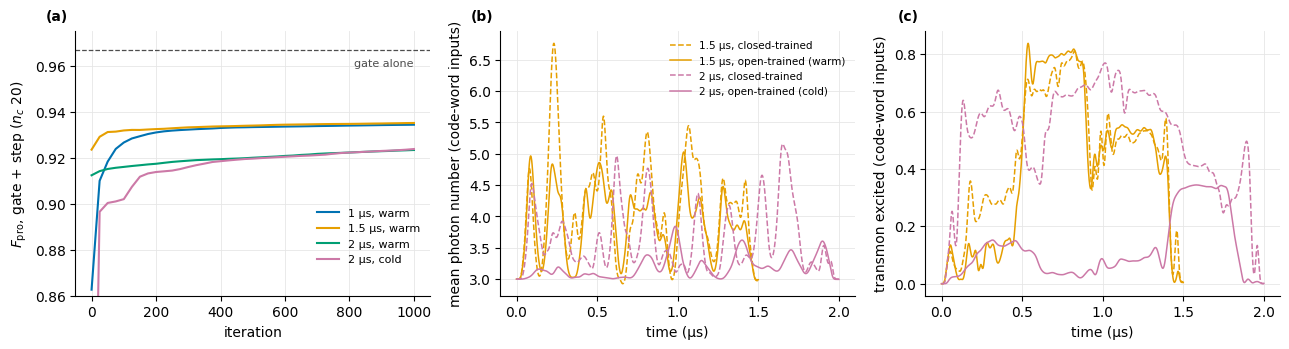

In [17]:
# Figure 4: (a) training curves; (b, c) photon number and transmon excitation along the pulse, closed vs open trained
from DGRAPE import aqec_pulse as ap
from EST.grape_eigh import propagate_trajectory
from DGRAPE.model import operators
import json

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
cols = dict(zip(OPEN, OKABE))
for tag, lab in OPEN.items():
    h = pd.DataFrame(json.load(open(f"pulses/dgrape/{tag}.json"))["history"])
    ax[0].plot(h.it, h.F_pro, color=cols[tag], label=lab)
alone = SINGLE.query("channels == 'decay' and protocol == 'gate alone'").F_pro.iloc[0]
ax[0].axhline(alone, color="0.3", ls="--", lw=0.9)
ax[0].text(1000, alone - 0.004, "gate alone", ha="right", va="top", fontsize=8, color="0.3")
ax[0].set_ylim(0.86, 0.975)
ax[0].set_xlabel("iteration"); ax[0].set_ylabel("$F_{\\rm pro}$, gate + step ($n_c$ 20)")
ax[0].legend(frameon=False, fontsize=8, loc="lower right", bbox_to_anchor=(1, 0.08))

sysA = ap.system(24)
ops = operators(24, 1)
nop, pop = np.real(np.diag(ops["n_a"])), np.real(np.diag(ops["Pe"]) + np.diag(ops["Pf"]))
for tag, ls in (("aqec_T15_s43", "--"), ("aqec_open_T15_w", "-"), ("aqec_T20_s42", "--"), ("aqec_open_T20_s42", "-")):
    u = np.load(f"pulses/dgrape/u_{tag}.npy")
    P = np.abs(propagate_trajectory(u, sysA.H0, sysA.Hc, sysA.inputs, ap.DT)) ** 2
    t = np.arange(P.shape[0]) * ap.DT
    col = OKABE[1] if "T15" in tag else OKABE[3]
    lab = {"aqec_T15_s43": "1.5 μs, closed-trained", "aqec_open_T15_w": "1.5 μs, open-trained (warm)",
           "aqec_T20_s42": "2 μs, closed-trained", "aqec_open_T20_s42": "2 μs, open-trained (cold)"}[tag]
    ax[1].plot(t, (P.transpose(0, 2, 1) @ nop)[:, :6].mean(1), color=col, ls=ls, lw=1.1, label=lab)
    ax[2].plot(t, (P.transpose(0, 2, 1) @ pop)[:, :6].mean(1), color=col, ls=ls, lw=1.1, label=lab)
ax[1].set_ylabel("mean photon number (code-word inputs)"); ax[2].set_ylabel("transmon excited (code-word inputs)")
ax[1].legend(frameon=False, fontsize=7.5)
for a_, letter in zip(ax, "abc"):
    if letter != "a":
        a_.set_xlabel("time (μs)")
    a_.grid(color="0.9", lw=0.6)
    for side in ("top", "right"):
        a_.spines[side].set_visible(False)
    a_.text(-0.02, 1.03, f"({letter})", transform=a_.transAxes, fontweight="bold", ha="right", va="bottom")
fig.tight_layout()
fig.savefig("figures/aqec_compare_open.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 4. Open-system training.**
- (a) $F_{\rm pro}$ after one gate + the step, every 25 iterations (the cold run starts at 0.70, below the axis).
- (b) Mean photon number along the pulse, averaged over the six code-word inputs, in the closed system: dashed = Section 5's closed-trained pulse, solid = open-trained (1.5 μs warm from the dashed one; 2 μs the cold run).
- (c) The same for the transmon excitation.

*Symbols:* the code words themselves hold 3 photons on average.

**What it shows.**
- **Most of the gain comes in the first 100 iterations**, then the curves flatten well below the gate alone.
- **The photon number stays near 3–4.** The code words already hold 3 photons, so a step of length $T$ loses about $3\kappa_a T$ (2 % per μs) whatever the pulse does. Open training cannot remove that cost.
- **What it can cut is the transmon excitation.** The cold 2 μs pulse keeps the transmon excited 12 % of the time on code-word inputs, against about 50 % for the closed-trained pulses.
- **The warm 1.5 μs pulse stays close to its closed parent**: open training trims its photon peaks (6.8 down to 5) but keeps its shape.

In [18]:
def n1_open(channels):
    s = OSINGLE.query("channels == @channels").pivot(index="label", columns="protocol", values="F_pro")
    c = PSINGLE.query("channels == @channels and protocol == 'real AQEC (as is)'").set_index("label").F_pro
    alone = SINGLE.query("channels == @channels and protocol == 'gate alone'").F_pro.iloc[0]
    cond = {"decay": "train", "all": "all_ch"}[channels]
    fwm = HELD.query("tag == 'X_tail_estg_T08_t2' and condition == @cond").F_pro.iloc[0]
    out = pd.DataFrame({"run": list(OPEN.values()),
                        "open-trained step": s.loc[list(OPEN), "real AQEC (as is)"].values,
                        "closed-trained step (Table 8)": [c[CLOSED_OF[t]] for t in OPEN],
                        "idle, same length": s.loc[list(OPEN), "idle, same length, Kerr undone"].values,
                        "ideal step, same length": s.loc[list(OPEN), "ideal AQEC, same length"].values,
                        "open-trained, closed system": s.loc[list(OPEN), "real AQEC, closed system (gate and step)"].values})
    out["vs gate alone"] = (out["open-trained step"] - alone).map(pct)
    out["vs idle"] = (out["open-trained step"] - out["idle, same length"]).map(pct)
    return out, alone, fwm


for ch, name in (("decay", "13a"), ("all", "13b")):
    t13, alone, fwm = n1_open(ch)
    show(t13, f"Table {name}. One EsT X gate + one open-trained AQEC step, "
              f"{'decay set' if ch == 'decay' else 'every channel'} (gate alone {alone:.4f}, gate + FWM tail {fwm:.4f})",
         {c: "{:.4f}" for c in t13.columns[1:6]})

run,open-trained step,closed-trained step (Table 8),"idle, same length","ideal step, same length","open-trained, closed system",vs gate alone,vs idle
"1 μs, warm",0.9343,0.8234,0.9215,0.9631,0.9988,-3.28 %,+1.28 %
"1.5 μs, warm",0.9351,0.9205,0.9114,0.9625,0.9993,-3.20 %,+2.36 %
"2 μs, warm",0.9234,0.9124,0.9015,0.9618,0.9994,-4.37 %,+2.18 %
"2 μs, cold",0.9238,0.9124,0.9015,0.9618,0.9987,-4.33 %,+2.23 %


run,open-trained step,closed-trained step (Table 8),"idle, same length","ideal step, same length","open-trained, closed system",vs gate alone,vs idle
"1 μs, warm",0.9150,0.8033,0.9067,0.9503,0.9988,-4.23 %,+0.83 %
"1.5 μs, warm",0.9093,0.8911,0.8956,0.9484,0.9993,-4.81 %,+1.36 %
"2 μs, warm",0.8948,0.8830,0.8847,0.9464,0.9994,-6.25 %,+1.01 %
"2 μs, cold",0.9026,0.8830,0.8847,0.9464,0.9987,-5.47 %,+1.79 %


**Table 13. One gate, then one open-trained step.** Columns:
- **closed-trained step:** Section 5's pulse of the same length (Table 8). For the cold 2 μs run, the 2 μs closed pulse.
- **idle, same length:** wait the step's whole duration (pulse + 1.2 μs window), Kerr phase undone for free.
- **ideal step, same length:** Section 2's perfect map with $\tau_1$ = the pulse length.
- **closed system:** the open-trained step with no losses anywhere.

**What it shows.**
- **The open-trained steps do repair.** They beat waiting the same time by +1.3 % to +2.4 % (decay set), so they are not just idling well.
- **They lose to the gate alone, by 3.2 % at best** (1.5 μs: 0.935 vs 0.967). They also lose to the FWM tail (0.970), and to the ideal step of the same length by 2.7 %.
- **Open training recovered 1.1–1.5 % over the closed-trained pulses** at 1.5 and 2 μs, and 11 % at 1 μs, where the closed pulse was poor.
- **The readout window still costs about 2.5 %.** The "no readout window" row reaches 0.96, close to the gate alone; the 1.2 μs of waiting after the repair is what sinks the step.
- **With every channel** the ranking is the same: 0.915 at best (1 μs), against 0.957 for the gate alone and 0.958 for the FWM tail.

In [19]:
t14 = OCHAN[["label", "channels", "F_real", "F_idle", "F_ideal"]].copy()
t14.insert(0, "run", t14.pop("label").map(OPEN))
t14["real − idle"] = (t14.F_real - t14.F_idle).map(pct)
t14.columns = ["run", "losses on", "open-trained step", "idle, same length", "ideal step, same length", "step − idle"]
show(t14, "Table 14. The open-trained step alone on the code words (no gate), one decay channel at a time (F_pro against I)",
     {c: "{:.4f}" for c in ("open-trained step", "idle, same length", "ideal step, same length")})
st = pd.concat([OCHAN.drop_duplicates("label").assign(run=lambda d: d.label.map(OPEN)),
                PCHAN.drop_duplicates("label").assign(run=lambda d: d.duration_us.map(lambda T: f"{T:g} μs, closed-trained"))])
st14 = st[["run", "nbar_code", "nbar_max", "P_exc_code", "P_exc_err", "losses_in_pulse"]].copy()
st14.columns = ["pulse", "mean photons (code inputs)", "max photons", "transmon excited (code inputs)",
                "transmon excited (error inputs)", "photon losses expected in the pulse"]
show(st14, "Table 14b. What each pulse does, closed system, time averages (closed-trained pulses from Table 9b)",
     {"mean photons (code inputs)": "{:.2f}", "max photons": "{:.1f}", "transmon excited (code inputs)": "{:.2f}",
      "transmon excited (error inputs)": "{:.2f}", "photon losses expected in the pulse": "{:.2%}"})

run,losses on,open-trained step,"idle, same length","ideal step, same length",step − idle
"1 μs, warm",closed,0.9982,1.0000,1.0000,-0.18 %
"1 μs, warm",photon loss,0.9570,0.9528,0.9737,+0.42 %
"1 μs, warm",transmon decay,0.9946,1.0000,1.0000,-0.54 %
"1 μs, warm",decay set,0.9535,0.9528,0.9734,+0.07 %
"1.5 μs, warm",closed,0.9983,1.0000,1.0000,-0.17 %
"1.5 μs, warm",photon loss,0.9554,0.9424,0.9735,+1.30 %
"1.5 μs, warm",transmon decay,0.9879,1.0000,1.0000,-1.21 %
"1.5 μs, warm",decay set,0.9453,0.9424,0.9730,+0.29 %
"2 μs, cold",closed,0.9983,1.0000,1.0000,-0.17 %
"2 μs, cold",photon loss,0.9435,0.9321,0.9731,+1.14 %


pulse,mean photons (code inputs),max photons,transmon excited (code inputs),transmon excited (error inputs),photon losses expected in the pulse
"1 μs, warm",3.72,5.2,0.21,0.39,2.74%
"1.5 μs, warm",3.89,5.7,0.41,0.44,4.29%
"2 μs, cold",3.19,4.4,0.12,0.43,4.70%
"2 μs, warm",3.60,5.5,0.44,0.61,5.30%
"1 μs, closed-trained",4.54,8.3,0.28,0.44,3.34%
"1.5 μs, closed-trained",4.14,7.1,0.44,0.43,4.56%
"2 μs, closed-trained",3.64,6.0,0.51,0.59,5.35%


**Table 14. The step alone on clean code words**, one decay channel at a time, against waiting the same time and the
ideal step. Table 14b compares the pulses, open- and closed-trained.

**What it shows.**
- **Photon loss.** The open steps lose 1.0–1.6 % less than idle, but 1.6–2.9 % more than the ideal step. A loss during the pulse is still not cleanly repaired.
- **Transmon decay** still costs 0.5–1.8 %, against 0 for the ideal step. The open-trained warm pulses keep the transmon excited 40–60 % of the time; the cold one only 12 % on code-word inputs.
- **The photon number hardly moves:** 3.2–3.9 on average, against 3.6 for the closed pulse. It cannot go much below the code's own 3.

In [20]:
o1 = OB1.pivot(index="N", columns="label", values="F_pro")
o2 = OB2.pivot(index="N", columns="label", values="F_pro")
t15 = pd.DataFrame({"N": NS, "gates only": p1.loc[NS, "gates only"].values})
for tag, lab in OPEN.items():
    t15[f"B1 {lab}"] = o1.loc[NS, tag].values
t15["B1 FWM tail"] = f1.loc[NS, "tail"].values
for tag, lab in OPEN.items():
    t15[f"B2 {lab}"] = o2.loc[NS, tag].values
t15["B2 FWM tail"] = fw2.loc[NS, "F_pro"].values
t15["B2 ideal (1 μs)"] = p2.loc[NS, "(gate + ideal AQEC) pairs"].values
show(t15, "Table 15. Repeated gates with the open-trained steps: B1 = N gates then one step, B2 = a step after every gate",
     {c: "{:.4f}" for c in t15.columns if c != "N"})

Nall = o1.index.values
rows = [{"correction": f"open-trained step, {lab}",
         "B1: beats gates only from N =": first_win(o1[tag].values, none),
         "B2: beats gates only from N =": first_win(o2[tag].values, none),
         "B2: loss per pair": rate(Nall, o2[tag].values), "B2 at N = 20": o2[tag].values[-1]}
        for tag, lab in OPEN.items()]
t16 = pd.concat([pd.DataFrame(rows), t10b], ignore_index=True)
show(t16, "Table 16. Break-even and the cost per pair, open-trained steps next to Table 11",
     {"B2: loss per pair": lambda x: f"{100 * x:.2f} %", "B2 at N = 20": "{:.4f}",
      "B1: beats gates only from N =": lambda x: x if isinstance(x, str) else ("never (N ≤ 20)" if pd.isna(x) else f"{int(x)}"),
      "B2: beats gates only from N =": lambda x: x if isinstance(x, str) else ("never (N ≤ 20)" if pd.isna(x) else f"{int(x)}")})

N,gates only,"B1 1 μs, warm","B1 1.5 μs, warm","B1 2 μs, warm","B1 2 μs, cold",B1 FWM tail,"B2 1 μs, warm","B2 1.5 μs, warm","B2 2 μs, warm","B2 2 μs, cold",B2 FWM tail,B2 ideal (1 μs)
1,0.9671,0.9343,0.9351,0.9234,0.9238,0.9703,0.9343,0.9351,0.9234,0.9238,0.9702,0.9631
2,0.9359,0.9130,0.9204,0.9073,0.9055,0.9533,0.8870,0.9008,0.8833,0.8746,0.9475,0.9495
3,0.9050,0.8916,0.9045,0.8901,0.8854,0.9345,0.8439,0.8697,0.8479,0.8289,0.9252,0.9366
5,0.8472,0.8466,0.8691,0.8536,0.8431,0.8954,0.7666,0.8132,0.7851,0.7461,0.8839,0.9121
10,0.7195,0.7357,0.7687,0.7527,0.7383,0.7864,0.6112,0.6936,0.6567,0.5761,0.7911,0.8548
15,0.6105,0.6360,0.6688,0.6554,0.6418,0.6823,0.4966,0.5973,0.5571,0.4494,0.7110,0.8024
20,0.5200,0.5518,0.5841,0.5717,0.5562,0.5932,0.4127,0.5196,0.4796,0.3580,0.6414,0.7546


correction,B1: beats gates only from N =,B2: beats gates only from N =,B2: loss per pair,B2 at N = 20
"open-trained step, 1 μs, warm",6,never (N ≤ 20),2.68 %,0.4127
"open-trained step, 1.5 μs, warm",4,never (N ≤ 20),2.15 %,0.5196
"open-trained step, 2 μs, warm",5,never (N ≤ 20),2.28 %,0.4796
"open-trained step, 2 μs, cold",6,never (N ≤ 20),2.93 %,0.3580
"real AQEC, 1.0 μs",18,never (N ≤ 20),3.18 %,0.1368
"real AQEC, 1.5 μs",5,never (N ≤ 20),2.78 %,0.3809
"real AQEC, 2.0 μs",5,never (N ≤ 20),2.61 %,0.3988
ideal AQEC,2,2,1.09 %,0.7546
"ideal AQEC, strict",2,2,1.47 %,0.6810
no readout window,1,1,0.79 %,0.8394


**Tables 15–16. Repeated gates with the open-trained steps.** Columns as in Tables 10–11.

**One step after N gates (B1).**
- The open-trained steps break even from N = 4 (1.5 μs) to N = 6.
- At N = 20 the 1.5 μs step reaches 0.584, about the closed-trained one (0.583), still below the FWM tail (0.593) and the ideal step (0.633).

**A step after every gate (B2).** This is where open training helps most.
- The 1.5 μs step loses 2.15 % per pair, against 2.6–2.8 % for the closed-trained pulses and 2.34 % per bare gate.
- At N = 20 it just ties no correction (0.5196 vs 0.5200), up from 0.38 for the closed-trained pulse. The FWM pairs reach 0.641 and the ideal step 0.755.
- The other three open-trained steps never beat no correction within N = 20.

**Why it stays behind.** Each step takes 2.5–3.2 μs (pulse + window), against 0.8 μs for the FWM tail. On code words
that already hold 3 photons, that time alone costs about 6 % in photon loss, which the next step can repair only in
part.

# 7. Conclusions and next steps

**Findings** (decay set; EsT X gate, Shirol's chip, odd kitten code).

1. **One gate: our FWM tail beats even a perfect Cornell AQEC.**
   - The tail gains +0.32 %; the ideal AQEC loses 0.40 % (with every channel: +0.03 % vs −0.70 %).
   - The ideal map is perfect, but during the 1.2 μs readout window about 2.5 % of the population loses a photon after the repair.
2. **Many gates: a perfect AQEC would win.**
   - After every gate, at N = 20: 0.755 against 0.641 for the FWM pairs.
   - It gets there because the map restores a loss exactly (FWM keeps at most 0.935 of it), and the reset clears the transmon excitation each gate leaves behind.
3. **A real AQEC pulse needs 2 μs on this chip, and then it loses badly.**
   - Closed-system fidelity: 1 μs is too short (0.87 at $n_c$ = 24); 1.5 μs gives 0.989 and 2 μs 0.9999.
   - In the open system the 2 μs step gives −5.5 % after one gate.
   - With a step after every gate it never beats no correction: 0.399 vs 0.520 at N = 20, while the FWM pairs reach 0.641.
4. **Why the real pulse falls so far below the ideal one.**
   - The 2 μs pulse holds 3.6 photons and keeps the transmon excited half the time, so photon loss (5.3 % of the population) and transmon decay (1.8 %) strike *during* the pulse.
   - It is not error transparent, so those errors come out scrambled rather than as clean error words.
   - The ideal step assumed the opposite: every loss before the map is undone.
5. **Training the step in the open system helps, but not enough** (Section 6).
   - The best step (1.5 μs) gives 0.935 after one gate, up from 0.921, against 0.967 for the gate alone.
   - It does repair: +1.4 % over waiting the same time. But the 1.2 μs window and the 3 photons the code words carry cost more than it repairs.
   - With a step after every gate it loses 2.15 % per pair (bare gate 2.34 %) and only ties no correction at N = 20 (0.520); the FWM pairs reach 0.641.
6. **On Shirol's chip, our FWM tail is the better correction against every real AQEC pulse, closed- or open-trained, in every protocol tested.** Only the ideal AQEC beats it, and only over several gates.

**Next steps.**
- **A fast unconditional reset instead of the 1.2 μs measurement**, for example via the readout resonator, as comb 2 of the FWM tail already does. Without the window even the open-trained step would sit near the gate alone (0.96), and the window is the largest single cost in every version of the step.
- **An EsT-style cost for the AQEC pulse**, so that a photon lost during it ends as a clean error word the next step can fix.
- **Training the step for repeated use**: open-trained on the output of several gates, or of gate + step pairs, as the FWM tails were in `FWM_tails.ipynb` §8.5.
- **A transmon reset at the end of the FWM tail**, which "strict" shows is worth several percent over a long chain.